# Complete Error Analysis of the Frozen EfficientNet-B0

I reproduce the historical test results and inspect **every** incorrect prediction, retaining the original five-grade annotation.

Run notebook 18 first. The audit found cross-split duplicates, so this is a review of the historical model, not a new independent evaluation. No training or threshold tuning occurs here.


In [1]:
from pathlib import Path
import os
import sys

project_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/dr_detection").is_dir() and (p / "configs").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook inside the project folder.")
sys.path.insert(0, str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".mplconfig"))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Project: {project_root}")


Project: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy


## 1. Reproduce all test predictions

The saved model is loaded without downloading pretrained weights. The input transform is the same as the training pipeline's evaluation transform. A checksum connects the outputs to the checkpoint and configuration.


In [2]:
import torch
from dr_detection.final_analysis import run_error_analysis

torch.set_num_threads(4)
analysis = run_error_analysis(project_root)
output_dir = project_root / "outputs/final_error_analysis"
print("Historical metrics reproduced:", analysis["historical_metrics_reproduced"])
print("Confusion counts:", analysis["confusion_counts"])
print("Device:", analysis["device"])
if not analysis["historical_metrics_reproduced"]:
    raise RuntimeError("Results differ from the historical metrics. Investigate before interpreting.")


Frozen B0 test inference:   0%|          | 0/23 [00:00<?, ?it/s]

Frozen B0 test inference:   4%|▍         | 1/23 [00:01<00:30,  1.37s/it]

Frozen B0 test inference:   9%|▊         | 2/23 [00:02<00:20,  1.04it/s]

Frozen B0 test inference:  13%|█▎        | 3/23 [00:02<00:16,  1.21it/s]

Frozen B0 test inference:  17%|█▋        | 4/23 [00:03<00:14,  1.32it/s]

...

Frozen B0 test inference:  91%|█████████▏| 21/23 [00:13<00:01,  1.66it/s]

Frozen B0 test inference:  96%|█████████▌| 22/23 [00:13<00:00,  1.79it/s]

Frozen B0 test inference: 100%|██████████| 23/23 [00:14<00:00,  1.75it/s]

Frozen B0 test inference: 100%|██████████| 23/23 [00:14<00:00,  1.59it/s]

Historical metrics reproduced: True
Confusion counts: {'TN': 198, 'FP': 1, 'FN': 3, 'TP': 164}
Device: mps


**Table 19.1. All historical test predictions (first ten displayed)**


In [3]:
predictions = pd.read_csv(output_dir / "table_19_1_all_test_predictions.csv")
display(predictions.head(10))


,image_path,diagnosis,true_label,id_code,predicted_label,dr_probability,outcome,exact_match_in_train_or_valid
0,data/raw/aptos2019/test_images/test_images/e4d...,0,0,e4dcca36ceb4,0,1.010281e-13,TN,False
1,data/raw/aptos2019/test_images/test_images/e4e...,2,1,e4e343eaae2a,1,9.999909e-01,TP,True
2,data/raw/aptos2019/test_images/test_images/e4f...,4,1,e4f12411fd85,1,1.000000e+00,TP,False
3,data/raw/aptos2019/test_images/test_images/e50...,0,0,e50b0174690d,0,7.632276e-09,TN,False
4,data/raw/aptos2019/test_images/test_images/e51...,0,0,e5197d77ec68,0,6.304685e-04,TN,False
5,data/raw/aptos2019/test_images/test_images/e52...,0,0,e529c5757d64,0,5.686798e-07,TN,False
6,data/raw/aptos2019/test_images/test_images/e52...,3,1,e52ed5c29c5e,1,9.999921e-01,TP,False
7,data/raw/aptos2019/test_images/test_images/e54...,2,1,e540d2e35d15,1,9.958605e-01,TP,False
8,data/raw/aptos2019/test_images/test_images/e55...,1,1,e55188915f9d,1,9.985082e-01,TP,False
9,data/raw/aptos2019/test_images/test_images/e58...,1,1,e580676516b0,1,9.999508e-01,TP,False


**Table 19.2. Every incorrect prediction**

No difficult examples are omitted. True labels refer to dataset annotations, not an independent medical examination. Scores are uncalibrated softmax outputs.


In [4]:
errors = pd.read_csv(output_dir / "table_19_2_all_errors.csv")
display(errors)


,image_path,diagnosis,true_label,id_code,predicted_label,dr_probability,outcome,exact_match_in_train_or_valid,conflicting_binary_label_in_train_or_valid,image_number,panel_file
0,data/raw/aptos2019/test_images/test_images/ea1...,1,1,ea15a290eb96,0,0.338645,FN,True,True,Image 19.1,image_19_1_ea15a290eb96_fn.png
1,data/raw/aptos2019/test_images/test_images/eed...,1,1,eed4afc8ec83,0,0.000726,FN,False,False,Image 19.2,image_19_2_eed4afc8ec83_fn.png
2,data/raw/aptos2019/test_images/test_images/f9a...,2,1,f9aa35187bf3,0,0.214598,FN,False,False,Image 19.3,image_19_3_f9aa35187bf3_fn.png
3,data/raw/aptos2019/test_images/test_images/eb6...,0,0,eb6b1f1c09db,1,0.999653,FP,False,False,Image 19.4,image_19_4_eb6b1f1c09db_fp.png


**Table 19.3. Reproduced historical metrics**


In [5]:
display(pd.read_csv(output_dir / "table_19_3_reproduced_metrics.csv"))


,accuracy,precision,recall,f1_score,roc_auc,specificity
0,0.989071,0.993939,0.982036,0.987952,0.998315,0.994975


**Table 19.4. Binary errors by the original severity grade**


In [6]:
display(pd.read_csv(output_dir / "table_19_4_errors_by_original_grade.csv"))


,diagnosis,support,errors,error_rate
0,0,199,1,0.005025
1,1,30,2,0.066667
2,2,87,1,0.011494
3,3,17,0,0.000000
4,4,33,0,0.000000


**Table 19.5. Exact train/validation counterparts of incorrectly predicted test images**


In [7]:
display(pd.read_csv(output_dir / "table_19_5_error_duplicate_counterparts.csv"))


,test_id,test_grade,counterpart_split,counterpart_id,counterpart_grade,binary_label_conflict
0,ea15a290eb96,1,train,1c9c583c10bf,0,True


## 2. Inspect every error

Each numbered panel contains the actual model input and two explanations: target logit No DR and target logit DR Present. Grad-CAM targets the final EfficientNet feature block. Each map is normalized independently, so color intensity must not be compared as an absolute contribution between classes or images.


**Image 19.1. FN: ea15a290eb96**

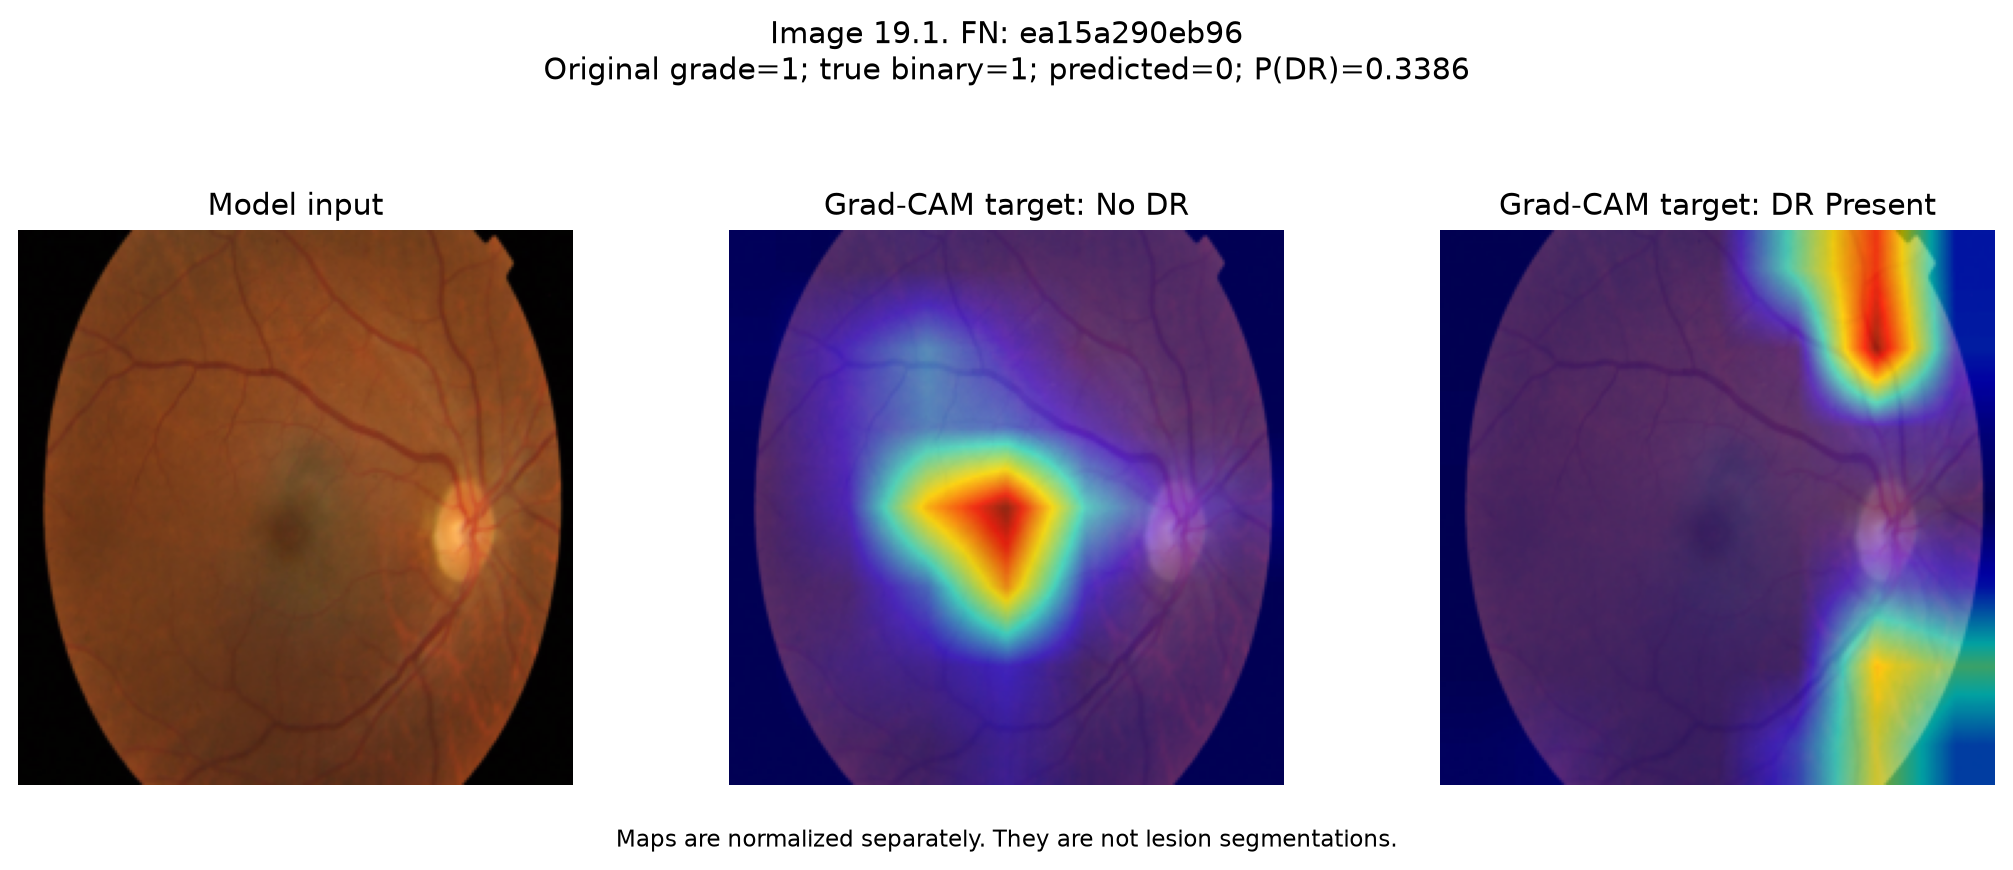

**Image 19.2. FN: eed4afc8ec83**

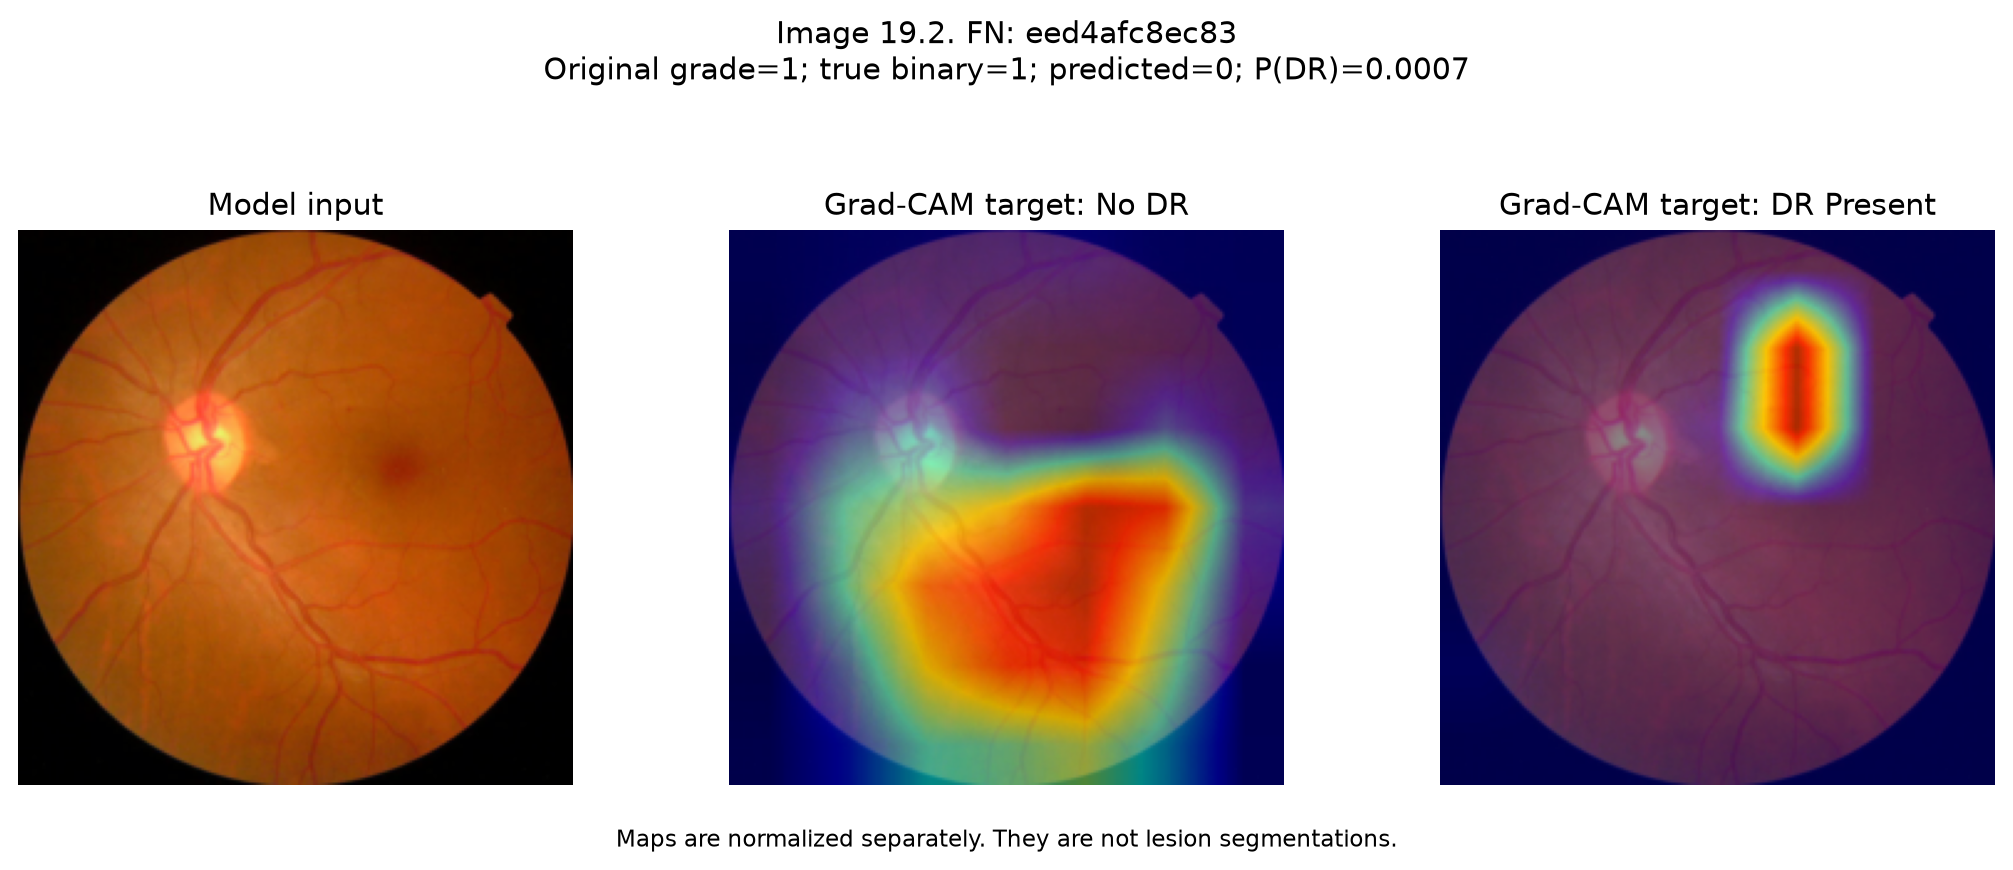

**Image 19.3. FN: f9aa35187bf3**

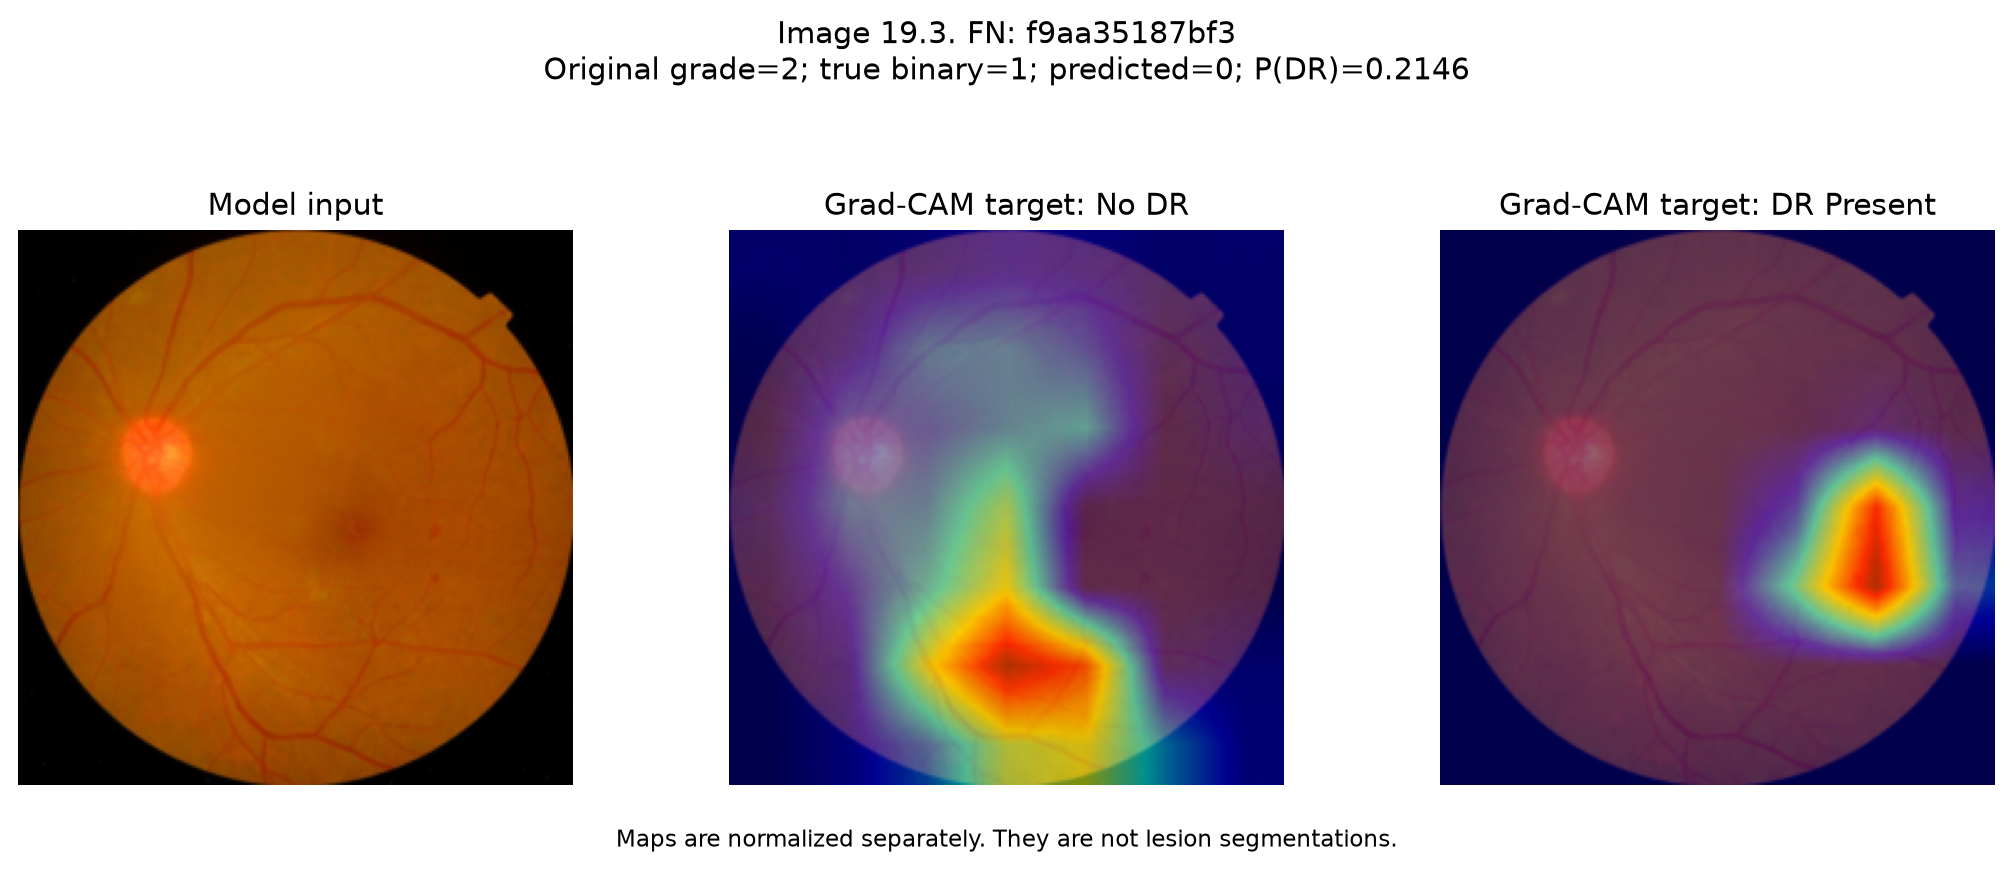

**Image 19.4. FP: eb6b1f1c09db**

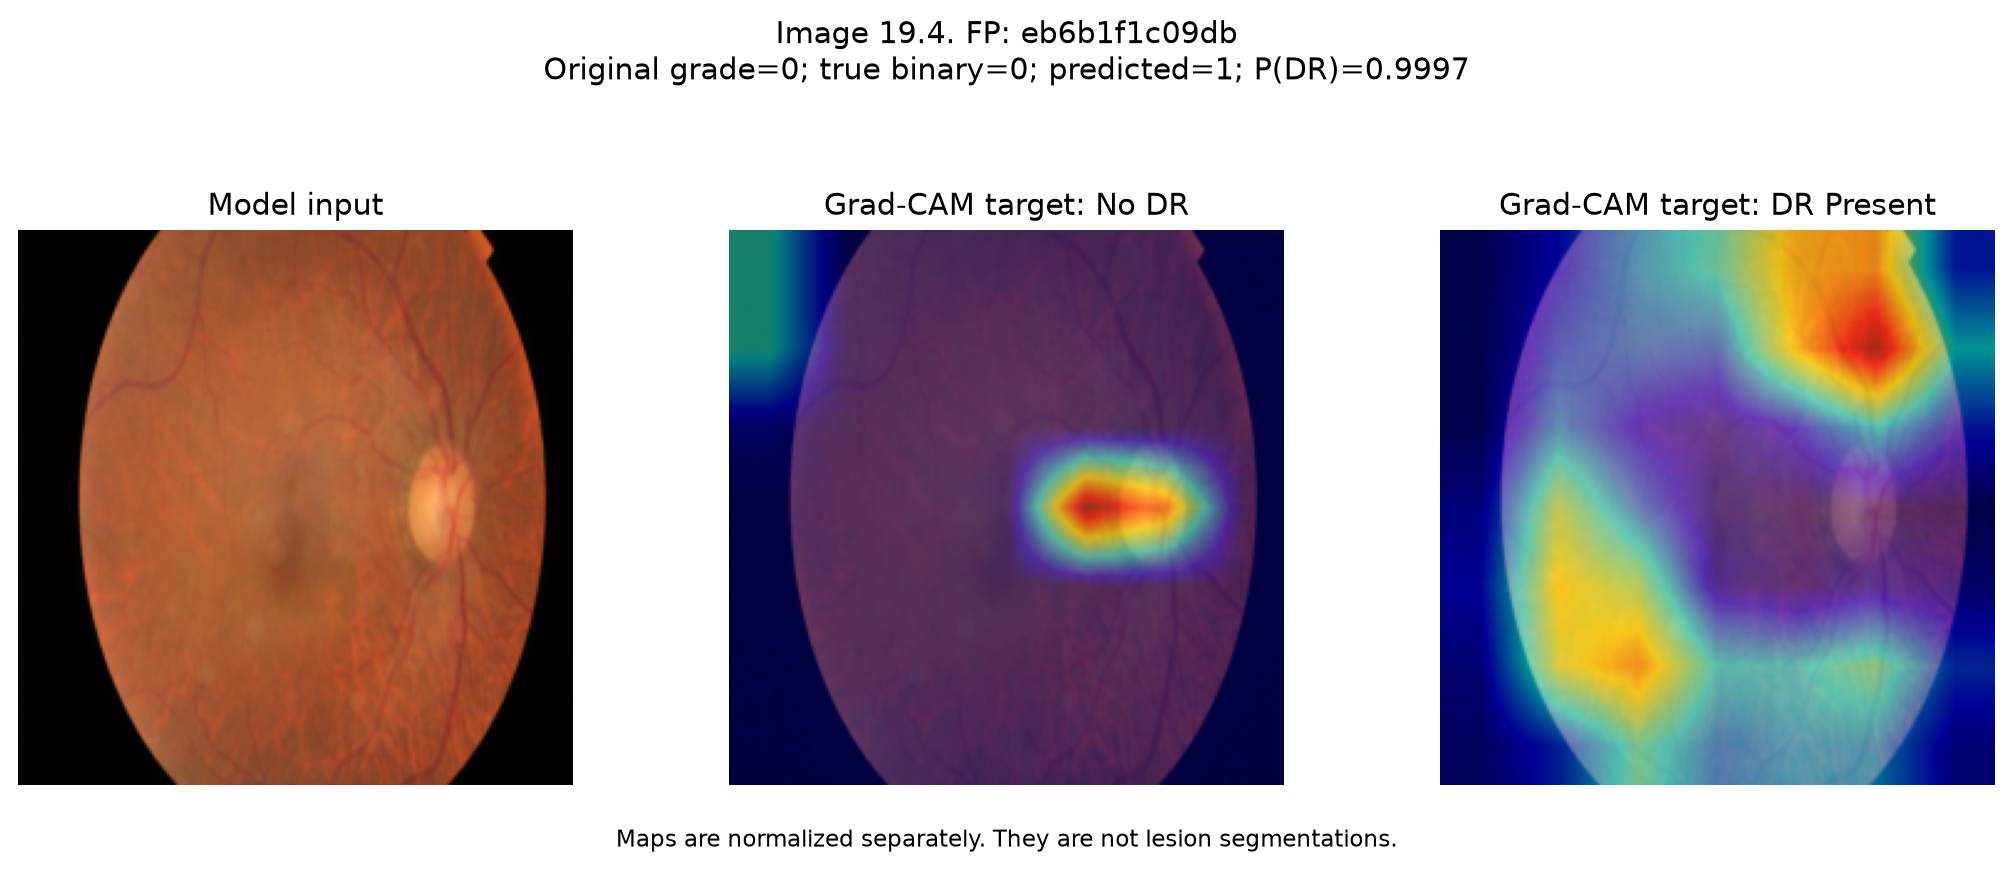

In [8]:
for row in errors.itertuples():
    display(Markdown(f"**{row.image_number}. {row.outcome}: {row.id_code}**"))
    display(DisplayImage(filename=str(output_dir / row.panel_file), width=1100))


## 3. Recorded interpretation of the four historical errors

- **Image 19.1, ea15a290eb96:** grade 1, predicted No DR, P(DR) approximately 0.339. Its exact training counterpart 1c9c583c10bf has grade 0. This is a contradictory annotation pair; I cannot attribute the mismatch solely to the network missing disease. The No DR map emphasizes the central region; the DR map emphasizes right-edge regions.
- **Image 19.2, eed4afc8ec83:** grade 1, predicted No DR, P(DR) approximately 0.00073. The incorrect prediction has a very high No DR score. The corresponding map covers a broad central/lower-right area. A high model score is not evidence that the annotation is wrong.
- **Image 19.3, f9aa35187bf3:** grade 2, predicted No DR, P(DR) approximately 0.215. The No DR map emphasizes a lower-central region and the DR map emphasizes a region to the right. These coarse maps do not establish whether particular lesions were detected.
- **Image 19.4, eb6b1f1c09db:** grade 0, predicted DR, P(DR) approximately 0.99965. The DR map is broad and emphasizes peripheral regions. This motivates further investigation of image-boundary cues; it does not prove a causal shortcut.

Two false negatives have grade 1 and one has grade 2. No false negatives were observed among the 17 grade-3 and 33 grade-4 test images, which is not a guarantee of perfect sensitivity on new severe cases.

These are visual observations and annotation checks, not lesion diagnoses. Lesion masks and an ophthalmologist's adjudication were not available. The original [Grad-CAM paper](https://arxiv.org/abs/1610.02391) describes class-specific coarse localization.

The thesis-ready account and next evaluation requirements are in `notes/FINAL_BINARY_REVIEW.md`.
